In [1]:
from obspy.core import read, Stream, Trace
from obspy.signal.filter import lowpass,highpass
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from geopy.distance import great_circle, geodesic
import warnings
import glob
import re
from pyproj import CRS, Transformer
import pickle
import xarray as xr
import xml.etree.ElementTree as ET
import datetime
import obspy
from shapely.geometry import Point, Polygon
import cartopy.crs as ccrs         # to plot maps with different projections
import cartopy.feature as cfeature # to plot coastlines, land, borders, etc.
import json
with open('/Users/zoekrauss/offshore_eew_modeling/location/PB2002_boundaries.json', 'r') as f:
    plate_boundaries = json.load(f)
import matplotlib
matplotlib.rcParams['font.family'] = ['Arial']
plt.rcParams.update({'font.size': 12}) 

## Read in station locations and the original mask

In [5]:
# station_locs = pd.read_csv('/Volumes/Extreme Pro/cascadia_2025_synthetics/offshore_seismic_feb2026.dat',delim_whitespace=True,header=None,
#                            names=['network','station','location','channel','lat','lon','x','fs','gain','units'])

station_locs = pd.read_csv('cascadia_mseeds/cascadia_mseeds_das.dat',delim_whitespace=True,header=None,
                           names=['network','station','location','channel','lat','lon','x','fs','gain','units'])

# # Below for including the midplate stations
# station_locs = pd.read_csv('/Users/zoekrauss/offshore_eew_modeling/replays/offshore_mseeds/offshore_seismic.dat',delim_whitespace=True,header=None,
#                            names=['network','station','location','channel','lat','lon','x','fs','gain','units'])

In [6]:
station_locs

,network,station,location,channel,lat,lon,x,fs,gain,units
0,NP,1023,--,ENE,40.57607,-124.26370,0.0,50.0,100000,counts/(cm/sec2)
1,NP,1023,--,ENN,40.57607,-124.26370,0.0,50.0,100000,counts/(cm/sec2)
2,NP,1023,--,ENZ,40.57607,-124.26370,0.0,50.0,100000,counts/(cm/sec2)
3,NP,1580,--,ENE,40.87772,-124.07738,0.0,50.0,100000,counts/(cm/sec2)
4,NP,1580,--,ENN,40.87772,-124.07738,0.0,50.0,100000,counts/(cm/sec2)
...,...,...,...,...,...,...,...,...,...,...
2182,CZ,00903,--,ENN,45.85460,-127.62436,0.0,50.0,100000,counts/(cm/sec2)
2183,CZ,00903,--,ENZ,45.85460,-127.62436,0.0,50.0,100000,counts/(cm/sec2)
2184,CZ,00904,--,ENE,45.86473,-127.36751,0.0,50.0,100000,counts/(cm/sec2)
2185,CZ,00904,--,ENN,45.86473,-127.36751,0.0,50.0,100000,counts/(cm/sec2)


In [7]:
stations_lat = [s for s in station_locs['lat']]
stations_lon = [s for s in station_locs['lon']]

In [8]:
len(stations_lon)

2187

In [9]:
ds = xr.open_dataset("/Users/zoekrauss/Downloads/WC_mask_75.0_noCondSusp_20240510.nc")
# ds = xr.open_dataset("/Users/zoekrauss/Downloads/buried-random-mur13-shallow.nc")
# ds = xr.open_dataset("/Users/zoekrauss/Downloads/CRAPMASKTEST_WC_mask_75.0_noCondSusp_20240510.nc")
# ds = xr.open_dataset("NEW_withOBS_WC_mask_75.0_noCondSusp_20240510.nc")

<frozen importlib._bootstrap>:219: RuntimeWarning: numpy.ndarray size changed, may indicate binary incompatibility. Expected 16 from C header, got 96 from PyObject


(40.0, 50.5)

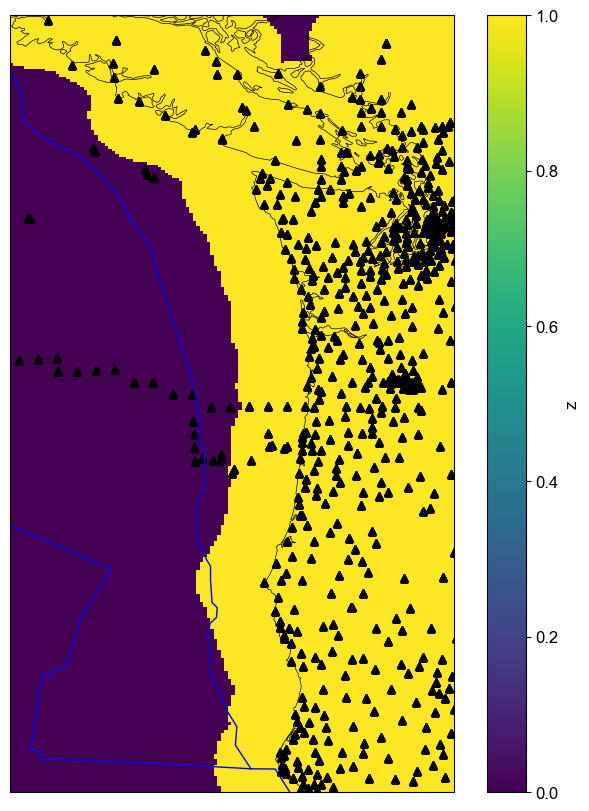

In [10]:
import xarray as xr
import matplotlib.pyplot as plt

fig = plt.figure(figsize=[8,8],constrained_layout=True)
ax=fig.add_subplot(projection=ccrs.PlateCarree(central_longitude=0))
ax.coastlines(linewidth=0.5)
ax.add_feature(cfeature.LAND, facecolor='honeydew') 
ax.add_feature(cfeature.OCEAN, facecolor='lightcyan',alpha=0.7)

ds['z'].plot()

ax.plot(station_locs['lon'],station_locs['lat'],'k^')

# Plot tectonic plate boundaries from local file
for feature in plate_boundaries['features']:
    coords = feature['geometry']['coordinates']
    if feature['geometry']['type'] == 'LineString':
        lons, lats = zip(*coords)
        ax.plot(lons, lats, color='blue', linewidth=1, transform=ccrs.PlateCarree())
    elif feature['geometry']['type'] == 'MultiLineString':
        for line in coords:
            lons, lats = zip(*line)
            ax.plot(lons, lats, color='blue', linewidth=1, transform=ccrs.PlateCarree())

ax.set_xlim(-128,-122)
ax.set_ylim(40,50.5)

## Edit mask to have a 1 for a 75 km radius around all stations

In [11]:
def haversine(lat1, lon1, lat2, lon2):
    R = 6371.0  # Earth radius (km)

    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = np.sin(dlat/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin(dlon/2)**2
    c = 2 * np.arcsin(np.sqrt(a))

    return R * c

In [12]:
lat2d, lon2d = xr.broadcast(ds.lat, ds.lon)

mask = np.zeros_like(lat2d, dtype=bool)

for slat, slon in zip(stations_lat, stations_lon):
    dist = haversine(lat2d, lon2d, slat, slon)
    mask |= (dist <= 75)

new_grid = xr.where(mask, 1, 0)

In [13]:
ds["station_radius_mask"] = xr.DataArray(
    new_grid.astype(int),
    coords={"lat": ds.lat, "lon": ds.lon},
    dims=("lat", "lon")
)

(40.0, 50.5)

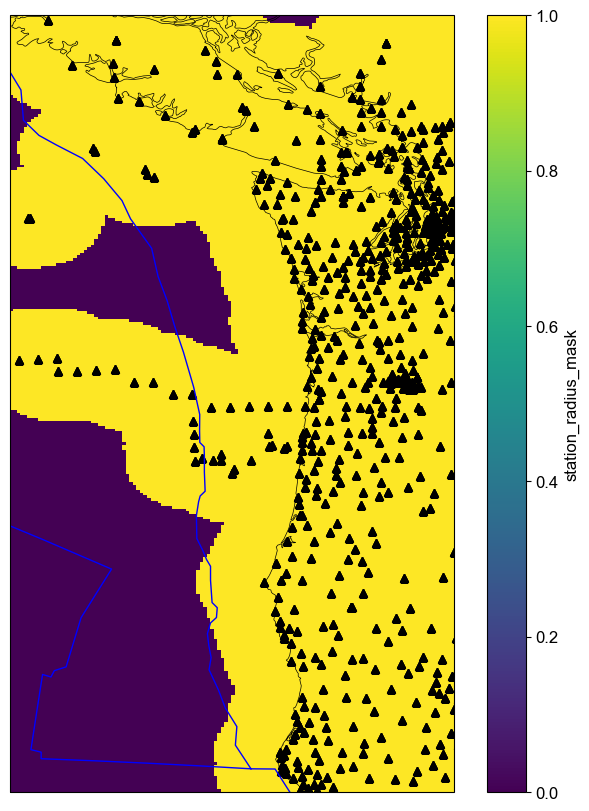

In [14]:
import xarray as xr
import matplotlib.pyplot as plt

fig = plt.figure(figsize=[8,8],constrained_layout=True)
ax=fig.add_subplot(projection=ccrs.PlateCarree(central_longitude=0))
ax.coastlines(linewidth=0.5)
ax.add_feature(cfeature.LAND, facecolor='honeydew') 
ax.add_feature(cfeature.OCEAN, facecolor='lightcyan',alpha=0.7)

ds['station_radius_mask'].plot()

ax.plot(station_locs['lon'],station_locs['lat'],'k^')

# Plot tectonic plate boundaries from local file
for feature in plate_boundaries['features']:
    coords = feature['geometry']['coordinates']
    if feature['geometry']['type'] == 'LineString':
        lons, lats = zip(*coords)
        ax.plot(lons, lats, color='blue', linewidth=1, transform=ccrs.PlateCarree())
    elif feature['geometry']['type'] == 'MultiLineString':
        for line in coords:
            lons, lats = zip(*line)
            ax.plot(lons, lats, color='blue', linewidth=1, transform=ccrs.PlateCarree())

ax.set_xlim(-128,-122)
ax.set_ylim(40,50.5)

## Save in the same way as original file

In [15]:
ds_og = xr.open_dataset("/Users/zoekrauss/Downloads/WC_mask_75.0_noCondSusp_20240510.nc")

In [16]:
ds_og

<xarray.Dataset>
Dimensions:  (lon: 341, lat: 588)
Coordinates:
  * lon      (lon) float64 -128.9 -128.8 -128.8 -128.7 ... -112.8 -112.8 -112.7
  * lat      (lat) float64 30.29 30.32 30.36 30.4 ... 51.35 51.38 51.42 51.46
Data variables:
    z        (lat, lon) float32 ...
Attributes:
    Conventions:  CF-1.7
    title:        Produced by grdmath
    history:      grdclip @GMTAPI@-S-I-G-G-G-N-000000 -G@GMTAPI@-S-O-G-G-G-Y-...
    GMT_version:  6.3.0 [64-bit] [MP]

In [17]:
# Replace the z variable with the new grid
# ds_og['z']=new_grid.astype('float32')
ds_og["z"] = xr.DataArray(
    new_grid.astype('float32'),
    coords={"lat": ds.lat, "lon": ds.lon},
    dims=("lat", "lon")
)

In [18]:
ds_og

<xarray.Dataset>
Dimensions:  (lon: 341, lat: 588)
Coordinates:
  * lon      (lon) float64 -128.9 -128.8 -128.8 -128.7 ... -112.8 -112.8 -112.7
  * lat      (lat) float64 30.29 30.32 30.36 30.4 ... 51.35 51.38 51.42 51.46
Data variables:
    z        (lat, lon) float32 0.0 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
Attributes:
    Conventions:  CF-1.7
    title:        Produced by grdmath
    history:      grdclip @GMTAPI@-S-I-G-G-G-N-000000 -G@GMTAPI@-S-O-G-G-G-Y-...
    GMT_version:  6.3.0 [64-bit] [MP]

In [19]:
ds_og.to_netcdf("NEW_withdas_WC_mask_75.0_noCondSusp_20240510.nc")